# Ergomed Group: public data and market view

PUBLIC DATA only (Companies House filings, ClinicalTrials.gov API v2, SEC filings, ECB). Collected 16 Nov 2026 by the scripts in `src/`. Figures on Ergomed are historical and dated; no person names are kept.

Independent case study based on public data · not affiliated with or endorsed by Ergomed Group.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
PUB = Path('..') / 'data' / 'public'
plt.rcParams.update({'figure.figsize': (8, 3.6), 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
BLUE, GREY, GREEN = '#2A78D6', '#C9C7BF', '#1BAF7A'

## 1. Ergomed Group in its filed accounts
Revenue by service line (CRO = Ergomed CRO, PV = PrimeVigilance) as printed in note 2 of each filing. GBP to FY2023 (Ergomed plc / Ergomed Group Limited); USD from the period to Dec 2024 (Eden TopCo Limited, 13.5 months of Ergomed results). The two currency blocks are not joined: no growth rate is computed across the break.

In [2]:
rev = pd.read_csv(PUB / 'ergomed_revenue.csv')
t = rev.pivot_table(index=['year', 'currency', 'period_months'], columns='business', values='revenue_thousands', aggfunc='sum') / 1000
t['Total'] = t.sum(axis=1); t['PV share'] = t.iloc[:, 1] / t['Total']
t.round(2)

,,business,Ergomed CRO (clinical research),PrimeVigilance (pharmacovigilance),Total,PV share
year,currency,period_months,,,,
2019,GBP,12.0,32.84,35.41,68.26,0.52
2020,GBP,12.0,31.32,55.08,86.39,0.64
2021,GBP,12.0,58.08,60.50,118.58,0.51
2022,GBP,12.0,71.36,73.90,145.26,0.51
2023,GBP,12.0,80.80,79.27,160.07,0.50
2024,USD,13.5,117.48,126.80,244.27,0.52
2025,USD,12.0,90.93,131.92,222.85,0.59


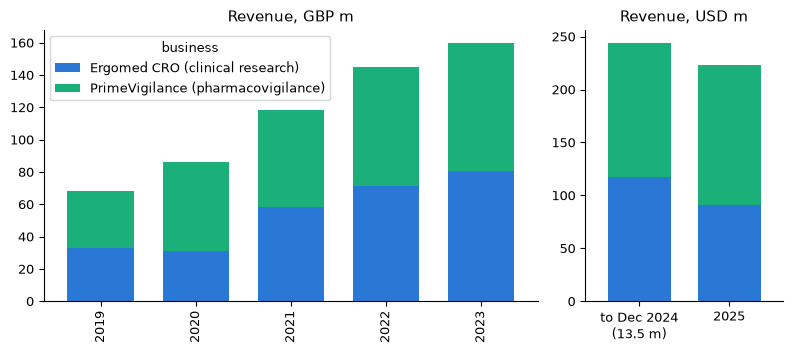

In [3]:
fig, axes = plt.subplots(1, 2, gridspec_kw={'width_ratios': [5, 2]})
for ax, ccy in zip(axes, ['GBP', 'USD']):
    d = t.xs(ccy, level='currency').droplevel('period_months')
    d.iloc[:, :2].plot.bar(stacked=True, ax=ax, color=[BLUE, GREEN], width=0.7, legend=ccy == 'GBP')
    ax.set_title(f'Revenue, {ccy} m'); ax.set_xlabel('')
axes[1].set_xticklabels(['to Dec 2024\n(13.5 m)', '2025'], rotation=0)
plt.tight_layout()

In [4]:
reg = rev.groupby(['year', 'client_region']).revenue_thousands.sum().unstack()
(reg.div(reg.sum(axis=1), axis=0) * 100).round(1)

client_region,Asia,Australia,North America,"Rest of Europe, Middle East and Africa",Rest of World,UK
year,,,,,,
2019,2.2,0.2,37.5,41.5,NaN,18.6
2020,4.7,0.2,54.0,27.0,NaN,14.1
2021,NaN,NaN,62.8,19.0,6.2,12.0
2022,NaN,NaN,62.3,20.1,3.6,13.9
2023,NaN,NaN,62.8,23.4,2.7,11.0
2024,NaN,NaN,56.4,32.6,4.8,6.2
2025,NaN,NaN,62.0,26.8,5.2,6.0


Order book and net awards (GBP m, narrative sections of the annual reports). Book-to-bill = net awards / revenue; 'implied' awards = change in order book + revenue (ignores acquisitions and FX).

In [5]:
com = pd.read_csv(PUB / 'ergomed_commercial.csv')
com[['year', 'order_book_m', 'net_awards_m', 'revenue_m', 'book_to_bill', 'implied_awards_m', 'implied_book_to_bill', 'cro_order_book_m', 'pv_order_book_m']]

,year,order_book_m,net_awards_m,revenue_m,book_to_bill,implied_awards_m,implied_book_to_bill,cro_order_book_m,pv_order_book_m
0,2018,109.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2019,124.1,NaN,68.3,NaN,83.2,1.22,69.5,54.6
2,2020,193.0,117.8,86.4,1.36,155.3,1.80,113.2,79.8
3,2021,239.7,165.3,118.6,1.39,165.3,1.39,NaN,NaN
4,2022,295.0,NaN,145.3,NaN,200.6,1.38,NaN,NaN
5,2023,324.2,NaN,160.1,NaN,189.3,1.18,NaN,NaN


### Reconciliation of the public figures
The same figure read in two places of the filings: what matches, what does not, and why.

In [6]:
pd.set_option('display.max_colwidth', 120)
pd.read_csv(PUB / 'reconciliation_public.csv')[['id', 'check', 'gap', 'status', 'explanation']]

,id,check,gap,status,explanation
0,R1,"Revenue FY2022, KPI table vs note 2",0.00,Reconciled,"Rounding only: same figure, millions vs thousands."
1,R2,Order book roll-forward 2021,0.00,Reconciled,Closes exactly: the published net awards are consistent with the order book and revenue.
2,R3,Order book roll-forward 2020,-37.50,Open - hypothesis,Gap of GBP 37.5m. Hypothesis (not confirmed in the filing): order books acquired with the two 2020 acquisitions and ...
3,R4,"Revenue by region FY2021, highlights vs note",-0.10,Reconciled - mapping,"Same total, different region boundaries: 'Asia' in the highlights vs 'Rest of World' in the note."
4,R5,Region list 2019-2020 vs 2021+,0.00,Reconciled - mapping,Taxonomy change: Asia + Australia merged into Rest of World. Mapping table needed for a time series.
5,R6,"Revenue prior period (to Dec 2024), note 2 total vs its rows",450.00,Reconciled - source typo,"Transposed digits in the printed total of the note; rows, the income statement and the narrative (USD 244.3m) agree ..."
6,R7,Comparability FY2023 -> FY2024,NaN,Documented,"Currency, period length and reporting entity all change. Not comparable without restating; growth rates across this ..."
7,R8,CRO service fee revenue FY2022,0.08,Open - small,"GBP 0.1m. Hypothesis: service fee = revenue minus reimbursable *revenue*, which the notes do not show separately fro..."


## 2. The market Ergomed sells into (ClinicalTrials.gov)
Interventional studies with an industry lead sponsor, started 2019-2025. Oncology = MeSH Neoplasms in the registry's condition index; rare disease = proxy (MeSH inborn genetic diseases, or 'rare' / 'orphan' in conditions or keywords). Sponsor size = studies started by the lead sponsor in the window.

In [7]:
s = json.loads((PUB / 'ct_summary.json').read_text())
{k: s[k] for k in ['studies', 'focus_studies', 'focus_share', 'small_mid_share_focus', 'small_mid_share_other', 'phase2_3_share_focus']}

{'studies': 38468,
 'focus_studies': 8693,
 'focus_share': 0.226,
 'small_mid_share_focus': 0.682,
 'small_mid_share_other': 0.734,
 'phase2_3_share_focus': 0.586}

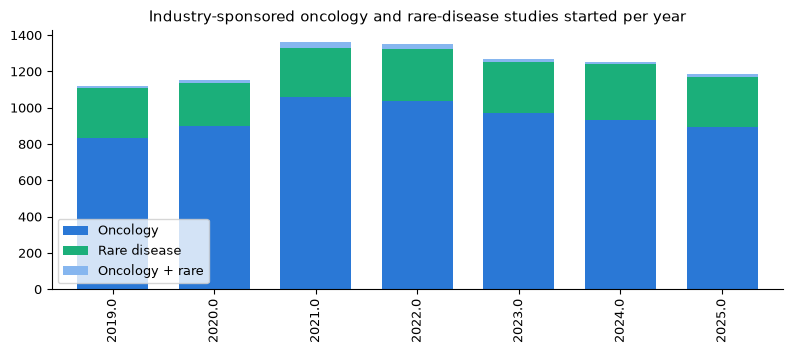

In [8]:
y = pd.read_csv(PUB / 'ct_by_year.csv', index_col=0)
ax = y[['Oncology', 'Rare disease', 'Oncology + rare']].plot.bar(stacked=True, color=[BLUE, GREEN, '#86B6EF'], width=0.7)
ax.set_title('Industry-sponsored oncology and rare-disease studies started per year'); ax.set_xlabel('')
plt.tight_layout()

In [9]:
ps = pd.read_csv(PUB / 'ct_by_phase_size.csv', index_col=0)
ps = ps.loc[[p for p in ['Phase I', 'Phase II', 'Phase III', 'Phase IV'] if p in ps.index]]
(ps.div(ps.sum(axis=1), axis=0) * 100).round(1)

,Large (51+),Mid (6-50),Small (1-5 studies)
phase,,,
Phase I,28.7,34.5,36.8
Phase II,30.4,33.4,36.3
Phase III,47.0,36.5,16.6
Phase IV,59.1,26.3,14.5


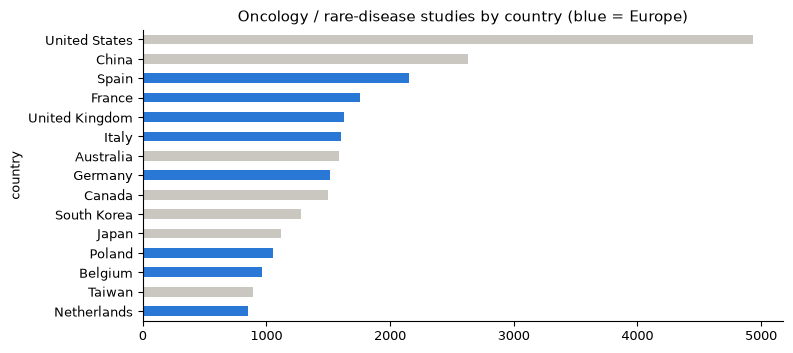

In [10]:
c = pd.read_csv(PUB / 'ct_by_country.csv', index_col=0).head(15)
ax = c.studies[::-1].plot.barh(color=[BLUE if r == 'Europe' else GREY for r in c.region[::-1]])
ax.set_title('Oncology / rare-disease studies by country (blue = Europe)'); plt.tight_layout()

In [11]:
pd.read_csv(PUB / 'ct_ergomed.csv').groupby(['role', 'phase']).size()

role          phase         
Collaborator  Not applicable    4
              Phase I           5
              Phase II          7
              Phase III         6
              Phase IV          2
dtype: int64

## 3. Competitor benchmarks (listed CROs)
Definitions differ (see `src/extract_competitors.py`); ICON changed its backlog method on 1 Oct 2025. Compare direction, not decimals.

In [12]:
comp = pd.read_csv(PUB / 'competitors.csv')
comp.pivot(index='year', columns='company', values='book_to_bill').round(2)

company,ICON,IQVIA (R&D Solutions),Medpace
year,,,
2019,NaN,NaN,NaN
2020,NaN,1.62,1.27
2021,NaN,1.29,1.41
2022,NaN,1.30,1.25
2023,NaN,1.30,1.25
2024,1.20,1.16,1.06
2025,1.09,1.18,1.05


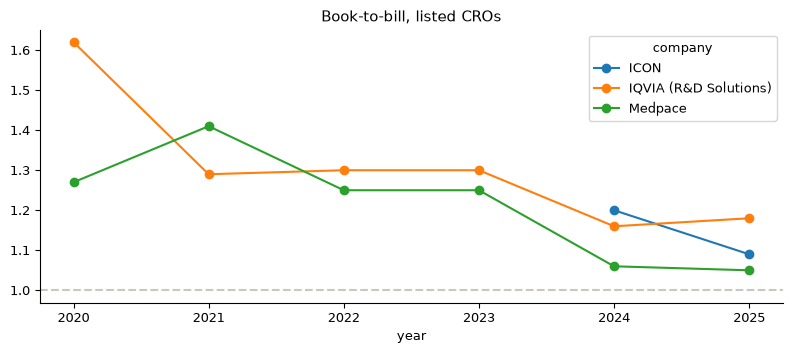

In [13]:
ax = comp.pivot(index='year', columns='company', values='book_to_bill').plot(marker='o')
ax.axhline(1, color=GREY, ls='--')
ax.set_title('Book-to-bill, listed CROs'); plt.tight_layout()

**Findings** - Oncology and rare disease are about a fifth of industry-sponsored interventional studies, and most of them are run by small and mid-size sponsors, the usual clients of a specialist mid-size CRO. Listed CROs reported book-to-bill between 1.0x and 1.2x in 2024-2025.

**Limitations** - the rare-disease flag is a proxy; sponsor size is measured by trial count, not revenue; registry data lag the real start of studies.